In [119]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from pmdarima import auto_arima
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import pandas as pd
import matplotlib.pyplot as plt
from regression_utils import *

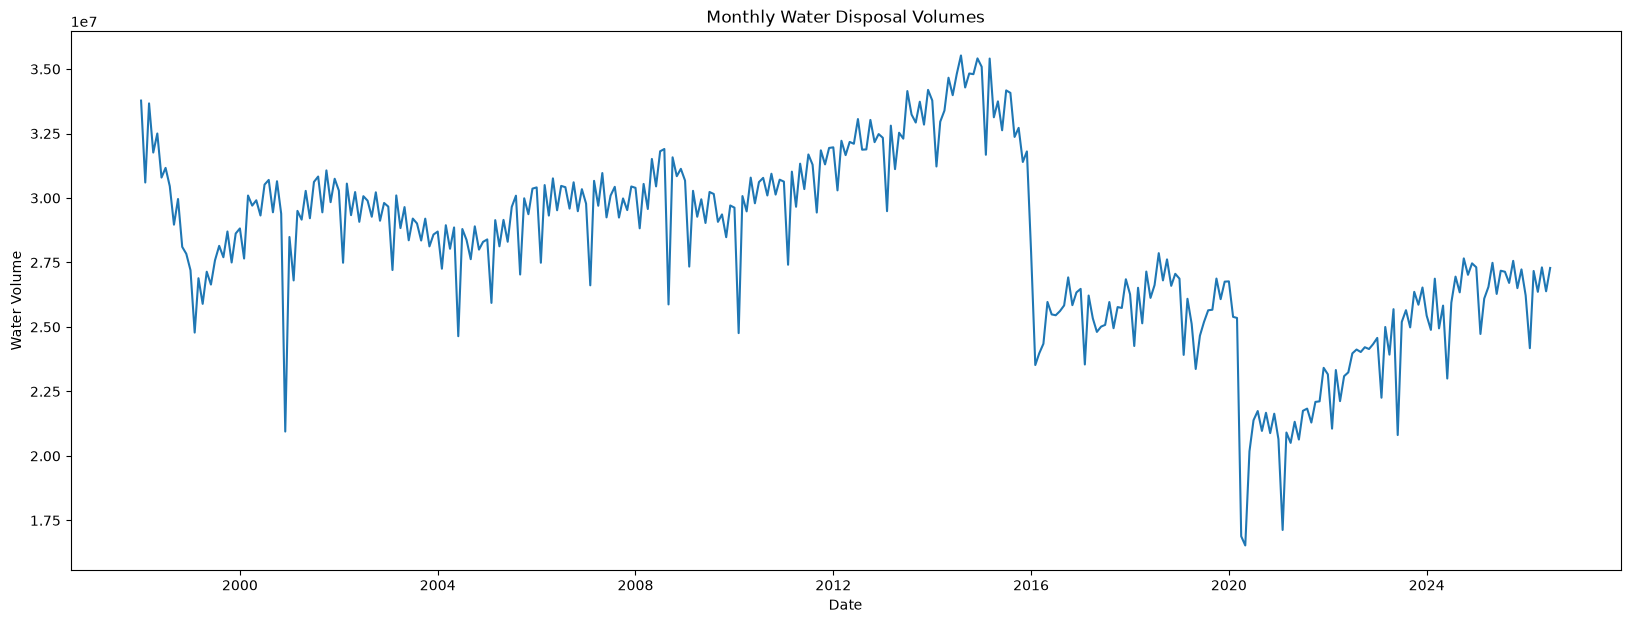

In [113]:
original_df = pd.read_excel(r"C:\Users\LoganFrideley\East Texas Salt Water Disposal Company\Finance - Documents\Water Disposal History.xlsx")

monthly_water_vols = original_df[['Month/ Year', 'Total Disposed Water Volume']].copy()

# Filter out all Na values for water volumes.
monthly_water_vols = monthly_water_vols[~monthly_water_vols['Total Disposed Water Volume'].isna()]

# Changing column names to 'Water Volume'
monthly_water_vols['Water Volume'] = monthly_water_vols['Total Disposed Water Volume']

# Changing column name to Date and also making the type datetime64
monthly_water_vols['Date'] = monthly_water_vols['Month/ Year']
monthly_water_vols['Date'] = pd.to_datetime(monthly_water_vols['Date'])

# Dropping the old columns
monthly_water_vols = monthly_water_vols.drop(columns = ['Total Disposed Water Volume', 'Month/ Year'])
# Changing the order of the columns
monthly_water_vols = monthly_water_vols.loc[:, ['Date', 'Water Volume']]


# Data is clean from the SARIMA script, I must figure out how to plot this data.

fig, ax = plt.subplots(figsize=(20,7))

ax.plot(monthly_water_vols['Date'], monthly_water_vols['Water Volume'], label = 'Water Disposal Volume')
ax.set_title('Monthly Water Disposal Volumes')
ax.set_xlabel('Date')
ax.set_ylabel('Water Volume')
fig.savefig("Monthly Water Volumes")
plt.show()            

ADF Statistic: -5.581762921632424
p-value: 1.3914529392114988e-06
Stationary


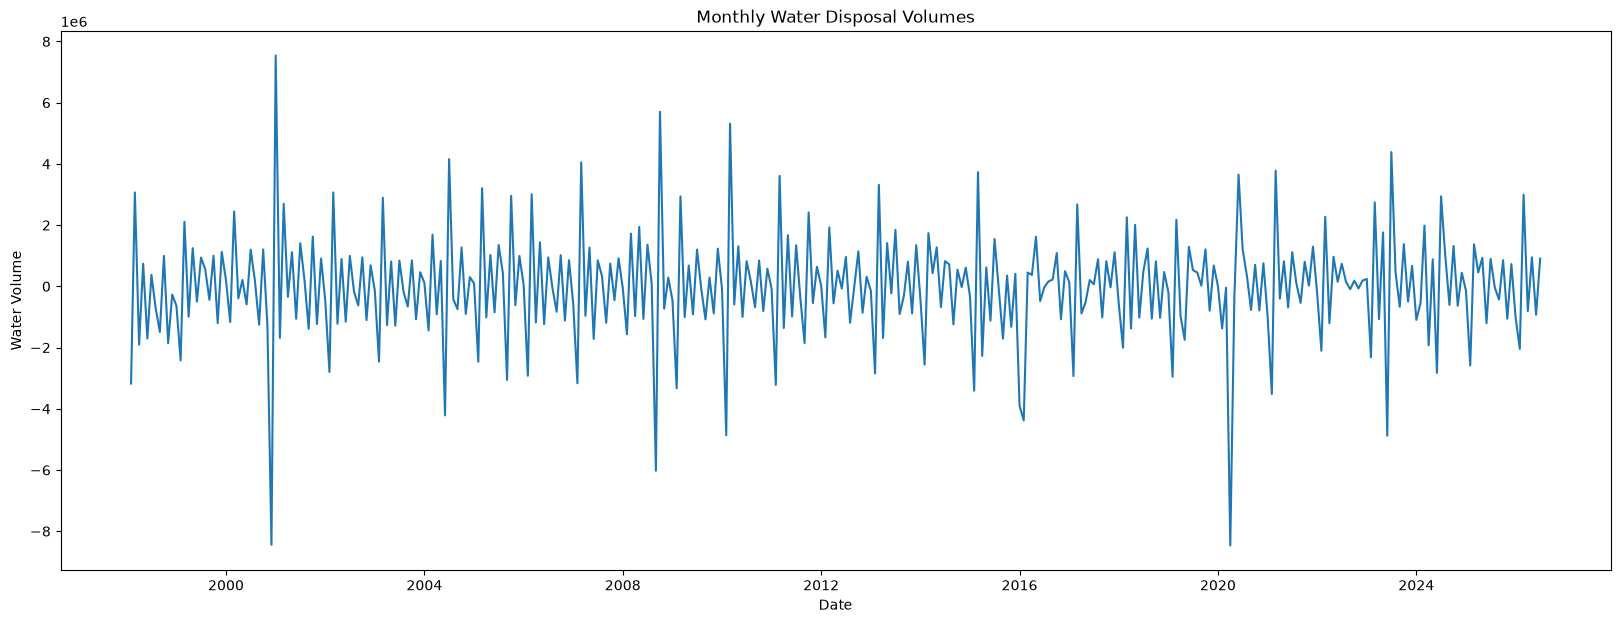

In [118]:


original_df = pd.read_excel(r"C:\Users\LoganFrideley\East Texas Salt Water Disposal Company\Finance - Documents\Water Disposal History.xlsx")

monthly_water_vols = original_df[['Month/ Year', 'Total Disposed Water Volume']].copy()

# Filter out all Na values for water volumes.
monthly_water_vols = monthly_water_vols[~monthly_water_vols['Total Disposed Water Volume'].isna()]

# Changing column names to 'Water Volume'
monthly_water_vols['Water Volume'] = monthly_water_vols['Total Disposed Water Volume']

# Changing column name to Date and also making the type datetime64
monthly_water_vols['Date'] = monthly_water_vols['Month/ Year']
monthly_water_vols['Date'] = pd.to_datetime(monthly_water_vols['Date'])

# Dropping the old columns
monthly_water_vols = monthly_water_vols.drop(columns = ['Total Disposed Water Volume', 'Month/ Year'])
# Changing the order of the columns
monthly_water_vols = monthly_water_vols.loc[:, ['Date', 'Water Volume']]

#Differenced the data by 1 and the set is stationary.
monthly_water_vols['diff1'] = monthly_water_vols['Water Volume'].diff(1)
cleaned = monthly_water_vols.dropna()


def check_stationarity(timeseries):
    result = adfuller(timeseries, autolag = 'AIC')
    p_value = result[1]
    print(f'ADF Statistic: {result[0]}')
    print(f'p-value: {p_value}')
    print('Stationary' if p_value < 0.05 else 'Non-stationary')

check_stationarity(cleaned['diff1'])
# Data is clean from the SARIMA script, I must figure out how to plot this data.

fig, ax = plt.subplots(figsize=(20,7))

ax.plot(monthly_water_vols['Date'], monthly_water_vols['diff1'], label = 'Water Disposal Volume')
ax.set_title('Monthly Water Disposal Volumes')
ax.set_xlabel('Date')
ax.set_ylabel('Water Volume')
fig.savefig("Monthly Water Volumes")
plt.show()            






C:\Users\LoganFrideley\AppData\Local\Temp\ipykernel_34588\2775600713.py:27: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  training = cleaned[training_mask]


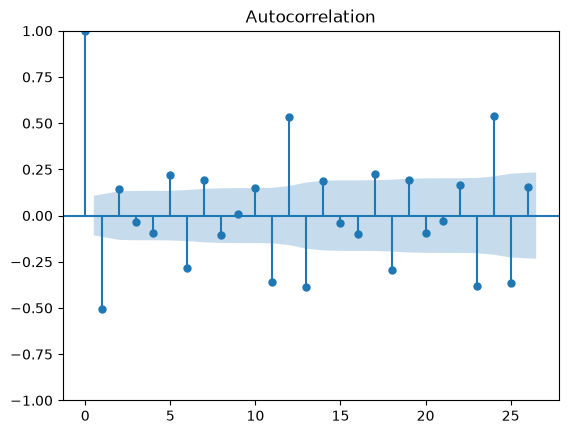

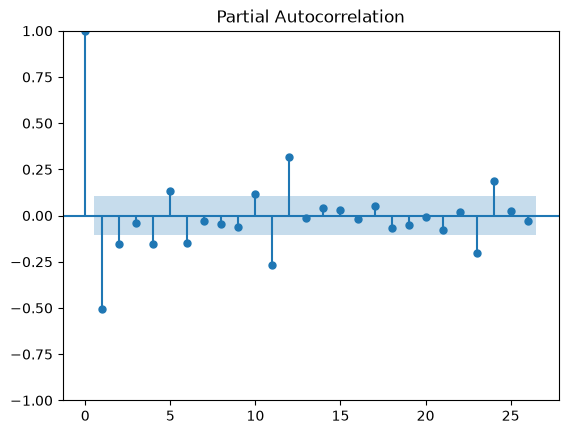

In [120]:

#AUTOCORRELATION FOR 1998 TO 2025
df = pd.read_excel(r"C:\Users\LoganFrideley\East Texas Salt Water Disposal Company\Finance - Documents\Water Disposal History.xlsx")

monthly_water_vols = df[['Month/ Year', 'Total Disposed Water Volume']].copy()
# Filter out all Na values for water volumes.
monthly_water_vols = monthly_water_vols[~monthly_water_vols['Total Disposed Water Volume'].isna()]
# Changing column names to 'Water Volume'
monthly_water_vols['Water Volume'] = monthly_water_vols['Total Disposed Water Volume']
# Changing column name to Date and also making the type datetime64
monthly_water_vols['Date'] = monthly_water_vols['Month/ Year']
monthly_water_vols['Date'] = pd.to_datetime(monthly_water_vols['Date'])


# change Date to a Period data type
#monthly_water_vols['Date'] = monthly_water_vols['Date'].dt.to_period(freq='M')


# Dropping the old columns
monthly_water_vols = monthly_water_vols.drop(columns = ['Total Disposed Water Volume', 'Month/ Year'])
# Changing the order of the columns
monthly_water_vols = monthly_water_vols.loc[:, ['Date', 'Water Volume']]

monthly_water_vols['diff1'] = monthly_water_vols['Water Volume'].diff(1)
cleaned = monthly_water_vols.dropna()

training_mask = (cleaned['Date'] >= '1998-01') & (monthly_water_vols['Date'] <= '2025-12')
training = cleaned[training_mask]

training_data_large = np.asarray(training['diff1'])
#Plotting ACF and PACF graphs
plot_acf(training_data_large)
plot_pacf(training_data_large)
plt.show()

In [10]:


original_df = pd.read_excel(r"C:\Users\LoganFrideley\East Texas Salt Water Disposal Company\Finance - Documents\Water Disposal History.xlsx")

monthly_water_vols = original_df[['Month/ Year', 'Total Disposed Water Volume']].copy()

# Filter out all Na values for water volumes.
monthly_water_vols = monthly_water_vols[~monthly_water_vols['Total Disposed Water Volume'].isna()]

# Changing column names to 'Water Volume'
monthly_water_vols['Water Volume'] = monthly_water_vols['Total Disposed Water Volume']

# Changing column name to Date and also making the type datetime64
monthly_water_vols['Date'] = monthly_water_vols['Month/ Year']
monthly_water_vols['Date'] = pd.to_datetime(monthly_water_vols['Date'])

# Dropping the old columns
monthly_water_vols = monthly_water_vols.drop(columns = ['Total Disposed Water Volume', 'Month/ Year'])
# Changing the order of the columns
monthly_water_vols = monthly_water_vols.loc[:, ['Date', 'Water Volume']]

#Differenced the data by 1 and the set is stationary.
monthly_water_vols['diff1'] = monthly_water_vols['Water Volume'].diff(1)
cleaned = monthly_water_vols.dropna()
#auto arima is called to find the correct parameters for the dataset
auto_arima(monthly_water_vols['Water Volume'], m = 12, trace = True).summary()

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,0,1)[12] intercept   : AIC=10658.504, Time=0.68 sec
 ARIMA(0,1,0)(0,0,0)[12] intercept   : AIC=10819.168, Time=0.01 sec
 ARIMA(1,1,0)(1,0,0)[12] intercept   : AIC=10728.371, Time=0.10 sec
 ARIMA(0,1,1)(0,0,1)[12] intercept   : AIC=10737.951, Time=0.15 sec
 ARIMA(0,1,0)(0,0,0)[12]             : AIC=10817.208, Time=0.01 sec
 ARIMA(2,1,2)(0,0,1)[12] intercept   : AIC=10739.365, Time=0.48 sec
 ARIMA(2,1,2)(1,0,0)[12] intercept   : AIC=10732.815, Time=0.51 sec
 ARIMA(2,1,2)(2,0,1)[12] intercept   : AIC=10655.033, Time=1.96 sec
 ARIMA(2,1,2)(2,0,0)[12] intercept   : AIC=10710.476, Time=1.59 sec
 ARIMA(2,1,2)(2,0,2)[12] intercept   : AIC=10654.816, Time=3.03 sec
 ARIMA(2,1,2)(1,0,2)[12] intercept   : AIC=10653.352, Time=1.46 sec
 ARIMA(2,1,2)(0,0,2)[12] intercept   : AIC=10730.334, Time=1.60 sec
 ARIMA(1,1,2)(1,0,2)[12] intercept   : AIC=10652.840, Time=1.39 sec
 ARIMA(1,1,2)(0,0,2)[12] intercept   : AIC=inf, Time=2.40 sec
 ARIMA(1,1,

<class 'statsmodels.iolib.summary.Summary'>
"""
                                        SARIMAX Results                                        
===============================================================================================
Dep. Variable:                                       y   No. Observations:                  343
Model:             SARIMAX(1, 1, 0)x(1, 0, [1, 2], 12)   Log Likelihood               -5320.096
Date:                                 Tue, 01 Sep 2026   AIC                          10650.191
Time:                                         14:46:49   BIC                          10669.365
Sample:                                              0   HQIC                         10657.830
                                                 - 343                                         
Covariance Type:                                   opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.1827      0.021     -8.707      0.000      -0.224      -0.142
ar.S.L12       0.8946      0.029     30.382      0.000       0.837       0.952
ma.S.L12      -0.8983      0.041    -22.070      0.000      -0.978      -0.819
ma.S.L24       0.1333      0.025      5.260      0.000       0.084       0.183
sigma2       2.33e+12   3.14e-15   7.42e+26      0.000    2.33e+12    2.33e+12
===================================================================================
Ljung-Box (L1) (Q):                   5.43   Jarque-Bera (JB):              1016.45
Prob(Q):                              0.02   Prob(JB):                         0.00
Heteroskedasticity (H):               0.70   Skew:                            -1.70
Prob(H) (two-sided):                  0.06   Kurtosis:                        10.73
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
[2] Covariance matrix is singular or near-singular, with condition number 1.89e+42. Standard errors may be unstable.
"""

C:\Users\LoganFrideley\AppData\Local\Temp\ipykernel_34588\1938202786.py:8: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  oil_prod['Date'] = pd.to_datetime(oil_prod['Date'])


Text(0.5, 1.0, 'Crude Oil Prices')

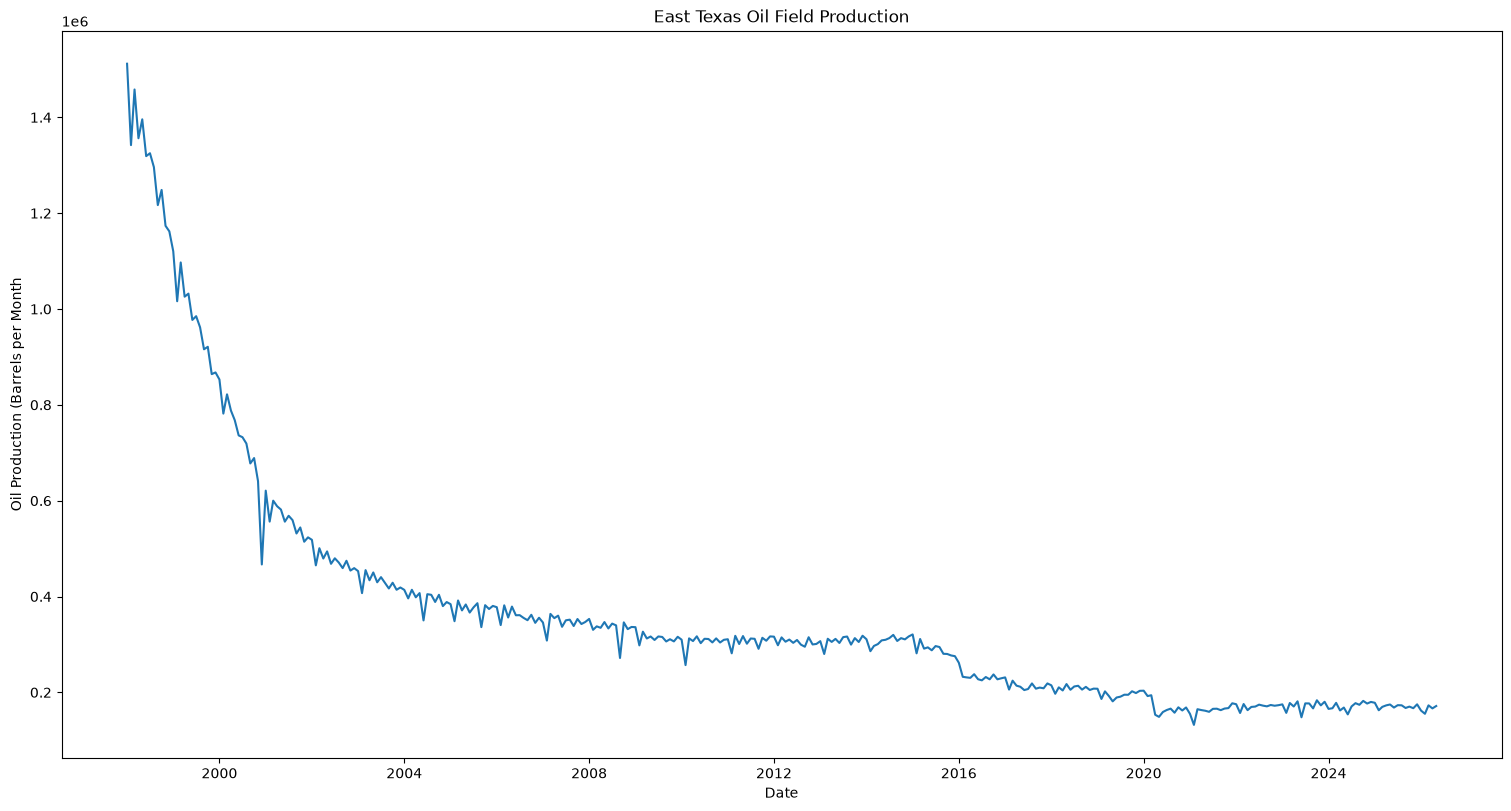

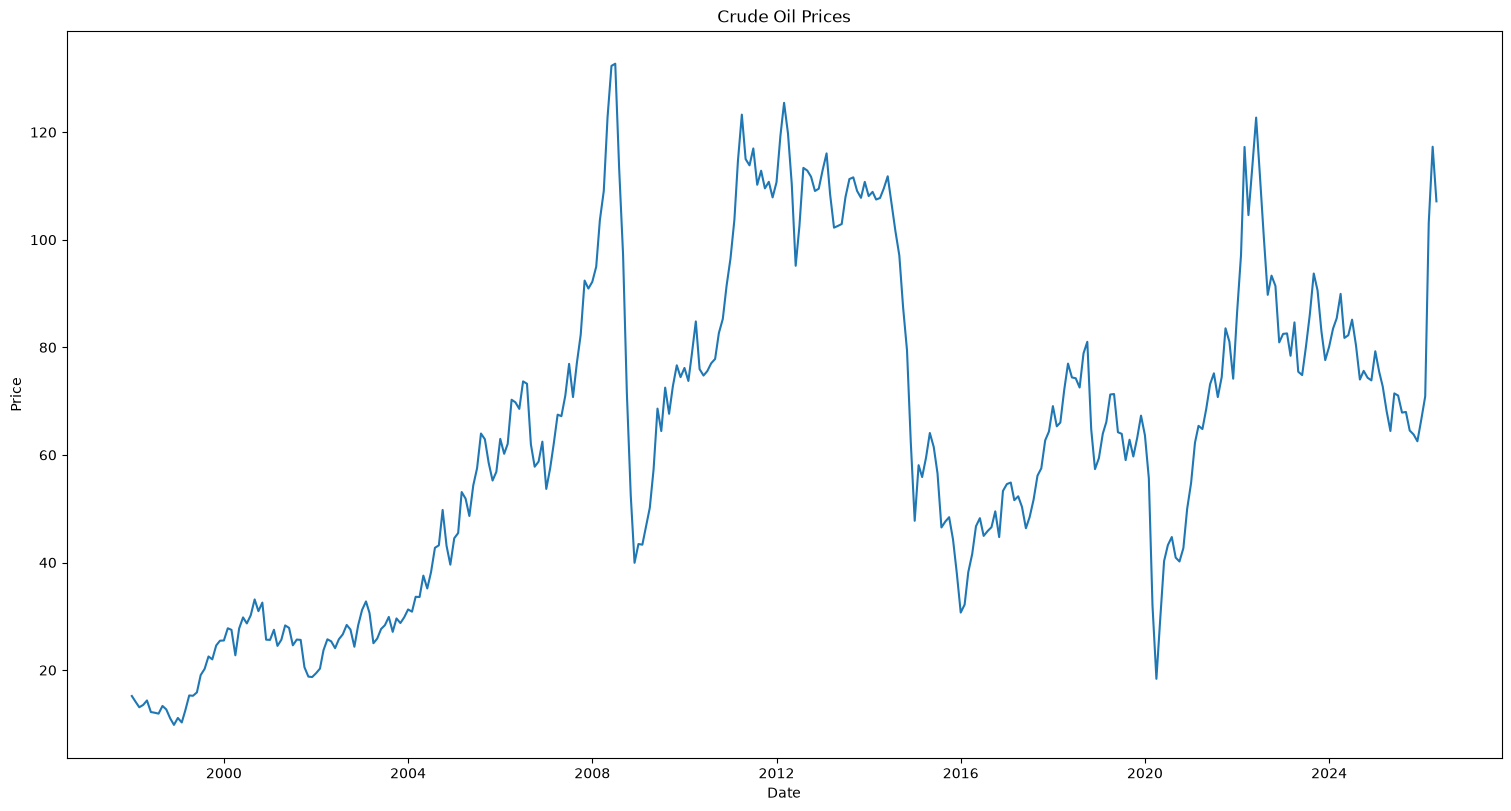

In [109]:
#This script is designed to read in the exogenous data collected in research.
#RRC oil barrel production
plt.ion()
df = pd.read_csv(r'C:\Users\LoganFrideley\OneDrive - East Texas Salt Water Disposal Company\Documents\SARIMA Project\ProductionDataQuery_monthlyTotals_ReportCsv(1).csv')


oil_prod = df[['Date', 'Barrels']].copy()
oil_prod['Date'] = pd.to_datetime(oil_prod['Date'])
oil_prod.sort_values('Date')

#FRED Brent-Crude oil pride index
df2 = pd.read_csv(r'C:\Users\LoganFrideley\OneDrive - East Texas Salt Water Disposal Company\Documents\SARIMA Project\MCOILBRENTEU.csv')

oil_price = df2[['Date', 'Price']].copy()
oil_price['Date'] = pd.to_datetime(oil_price['Date'])
oil_price.sort_values('Date')




#Figure for the oil_prod dataframe
fig, ax = plt.subplots(figsize=(15,8), layout = 'constrained')
ax.plot(oil_prod['Date'], oil_prod['Barrels'])
ax.set_xlabel('Date')
ax.set_ylabel('Oil Production (Barrels per Month')
ax.set_title('East Texas Oil Field Production')

#figure for the oil_price dataframe
fig, ax = plt.subplots(figsize=(15,8), layout = 'constrained')
ax.plot(oil_price['Date'], oil_price['Price'])
ax.set_xlabel('Date')
ax.set_ylabel('Price')
ax.set_title('Crude Oil Prices')


C:\Users\LoganFrideley\AppData\Local\Temp\ipykernel_34588\898429975.py:28: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  oil_prod['Date'] = pd.to_datetime(oil_prod['Date'])
C:\Users\LoganFrideley\anaconda3\envs\Analytics\Lib\site-packages\statsmodels\tsa\statespace\representation.py:374: FutureWarning: Unknown keyword arguments: dict_keys(['k_exog']).Passing unknown keyword arguments will raise a TypeError beginning in version 0.15.
  warnings.warn(msg, FutureWarning)


R-squared: 0.17625991465888036
Adjusted R-squared: -0.23561012801167935
                                        SARIMAX Results                                        
Dep. Variable:                            Water Volume   No. Observations:                  328
Model:             SARIMAX(1, 1, 0)x(1, 0, [1, 2], 12)   Log Likelihood               -4969.505
Date:                                 Thu, 03 Sep 2026   AIC                           9953.010
Time:                                         10:47:02   BIC                           9979.539
Sample:                                              0   HQIC                          9963.595
                                                 - 328                                         
Covariance Type:                                   opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Ba

C:\Users\LoganFrideley\AppData\Local\Temp\ipykernel_34588\898429975.py:83: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


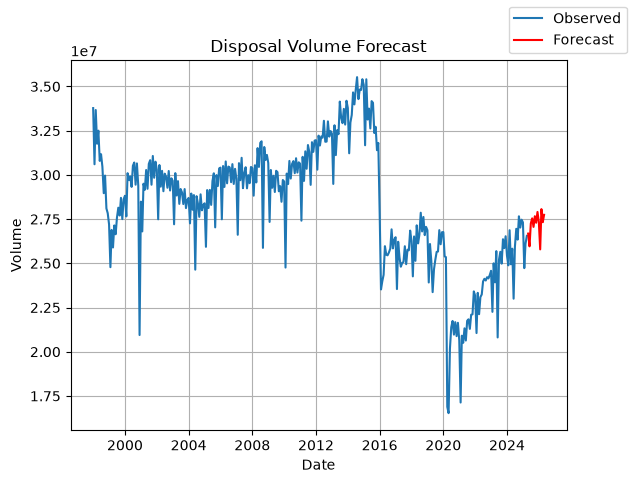

In [110]:
#Using the SARIMAX model with the exogenous variables
#Adding the oil production and price to the disposal volume dataframe
original_df = pd.read_excel(r"C:\Users\LoganFrideley\East Texas Salt Water Disposal Company\Finance - Documents\Water Disposal History.xlsx")

monthly_water_vols = original_df[['Month/ Year', 'Total Disposed Water Volume']].copy()

# Filter out all Na values for water volumes.
monthly_water_vols = monthly_water_vols[~monthly_water_vols['Total Disposed Water Volume'].isna()]

# Changing column names to 'Water Volume'
monthly_water_vols['Water Volume'] = monthly_water_vols['Total Disposed Water Volume']

# Changing column name to Date and also making the type datetime64
monthly_water_vols['Date'] = monthly_water_vols['Month/ Year']
monthly_water_vols['Date'] = pd.to_datetime(monthly_water_vols['Date'])

# Dropping the old columns
monthly_water_vols = monthly_water_vols.drop(columns = ['Total Disposed Water Volume', 'Month/ Year'])
# Changing the order of the columns
monthly_water_vols = monthly_water_vols.loc[:, ['Date', 'Water Volume']]


plt.ion()
df = pd.read_csv(r'C:\Users\LoganFrideley\OneDrive - East Texas Salt Water Disposal Company\Documents\SARIMA Project\ProductionDataQuery_monthlyTotals_ReportCsv(1).csv')


oil_prod = df[['Date', 'Barrels']].copy()
oil_prod['Date'] = pd.to_datetime(oil_prod['Date'])
oil_prod.sort_values('Date')

#FRED Brent-Crude oil pride index
df2 = pd.read_csv(r'C:\Users\LoganFrideley\OneDrive - East Texas Salt Water Disposal Company\Documents\SARIMA Project\MCOILBRENTEU.csv')

oil_price = df2[['Date', 'Price']].copy()
oil_price['Date'] = pd.to_datetime(oil_price['Date'])
oil_price.sort_values('Date')

#Combining the dataframes together for the SARIMA model
monthly_water_vols = monthly_water_vols.merge(oil_prod[['Date','Barrels']], on = 'Date', how = 'left')
monthly_water_vols = monthly_water_vols.merge(oil_price[['Date','Price']], on = 'Date', how = 'left')
monthly_water_vols = monthly_water_vols.dropna()


#Changing the dataframe to represent the last 5 years.
mask = (monthly_water_vols['Date'] >= '1998-01-01') & (monthly_water_vols['Date'] <= '2026-05-01')
subset = monthly_water_vols[mask]

#Assigning Training data set
training_mask = (subset['Date'] >= '1998-01-01') & (subset['Date'] <= '2025-04-01')
training = subset[training_mask]

#Assigning Validation data
validation_mask = (subset['Date'] >= '2025-05-01') & (subset['Date'] <= '2026-05-01')
validation = subset[validation_mask]

#SARIMAX model takes in the training data with two exogenous variables 
model = SARIMAX(
    training['Water Volume'], 
    k_exog = 2,
    exog = training[['Barrels', 'Price']], 
    order = (1,1,0), 
    seasonal_order = (1,0,2,12)
    
)
results = model.fit()
forecast_periods = len(validation)
forecast = results.forecast(forecast_periods, exog = validation[['Barrels', 'Price']])
r_squared = R_squared(validation['Water Volume'], forecast)
adjusted = adj_R_squared(validation['Water Volume'], forecast, monthly_water_vols)

print(f'R-squared: {r_squared}')
print(f'Adjusted R-squared: {adjusted}')
print(results.summary())

fig, ax = plt.subplots()
ax.plot(training['Date'], training['Water Volume'], label='Observed')
ax.plot(validation['Date'], forecast, label='Forecast', color='red')
ax.set_title("Disposal Volume Forecast")
ax.set_xlabel("Date")
ax.set_ylabel("Volume")
ax.grid()
fig.legend()
fig.show()


C:\Users\LoganFrideley\AppData\Local\Temp\ipykernel_34588\1003808205.py:29: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  oil_prod['Date'] = pd.to_datetime(oil_prod['Date'])
C:\Users\LoganFrideley\anaconda3\envs\Analytics\Lib\site-packages\statsmodels\tsa\statespace\representation.py:374: FutureWarning: Unknown keyword arguments: dict_keys(['k_exog']).Passing unknown keyword arguments will raise a TypeError beginning in version 0.15.
  warnings.warn(msg, FutureWarning)
C:\Users\LoganFrideley\anaconda3\envs\Analytics\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'


Adjusted R-squared: 0.6186355032285233
R-squared: 0.8365580728122243
                                        SARIMAX Results                                        
Dep. Variable:                            Water Volume   No. Observations:                   57
Model:             SARIMAX(1, 1, 0)x(1, 0, [1, 2], 12)   Log Likelihood                -795.278
Date:                                 Thu, 03 Sep 2026   AIC                           1604.555
Time:                                         10:39:08   BIC                           1618.733
Sample:                                              0   HQIC                          1610.052
                                                  - 57                                         
Covariance Type:                                   opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Barre

C:\Users\LoganFrideley\AppData\Local\Temp\ipykernel_34588\1003808205.py:83: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


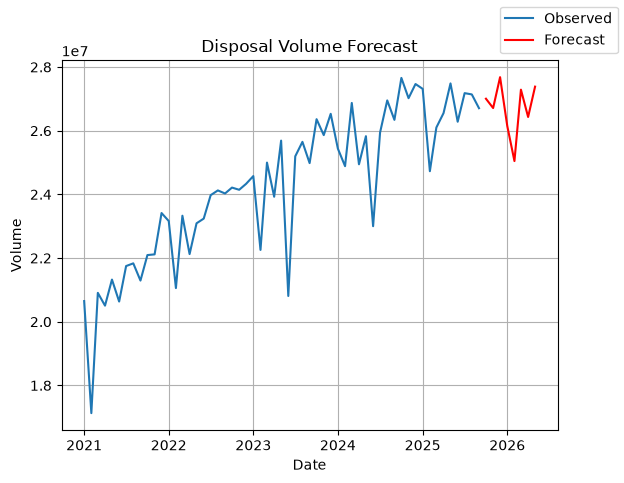

In [108]:
#This script showcases the model after COVID
#Using the SARIMAX model with the exogenous variables
#Adding the oil production and price to the disposal volume dataframe
original_df = pd.read_excel(r"C:\Users\LoganFrideley\East Texas Salt Water Disposal Company\Finance - Documents\Water Disposal History.xlsx")

monthly_water_vols = original_df[['Month/ Year', 'Total Disposed Water Volume']].copy()

# Filter out all Na values for water volumes.
monthly_water_vols = monthly_water_vols[~monthly_water_vols['Total Disposed Water Volume'].isna()]

# Changing column names to 'Water Volume'
monthly_water_vols['Water Volume'] = monthly_water_vols['Total Disposed Water Volume']

# Changing column name to Date and also making the type datetime64
monthly_water_vols['Date'] = monthly_water_vols['Month/ Year']
monthly_water_vols['Date'] = pd.to_datetime(monthly_water_vols['Date'])

# Dropping the old columns
monthly_water_vols = monthly_water_vols.drop(columns = ['Total Disposed Water Volume', 'Month/ Year'])
# Changing the order of the columns
monthly_water_vols = monthly_water_vols.loc[:, ['Date', 'Water Volume']]


plt.ion()
df = pd.read_csv(r'C:\Users\LoganFrideley\OneDrive - East Texas Salt Water Disposal Company\Documents\SARIMA Project\ProductionDataQuery_monthlyTotals_ReportCsv(1).csv')


oil_prod = df[['Date', 'Barrels']].copy()
oil_prod['Date'] = pd.to_datetime(oil_prod['Date'])
oil_prod.sort_values('Date')

#FRED Brent-Crude oil pride index
df2 = pd.read_csv(r'C:\Users\LoganFrideley\OneDrive - East Texas Salt Water Disposal Company\Documents\SARIMA Project\MCOILBRENTEU.csv')

oil_price = df2[['Date', 'Price']].copy()
oil_price['Date'] = pd.to_datetime(oil_price['Date'])
oil_price.sort_values('Date')

#Combining the dataframes together for the SARIMA model
monthly_water_vols = monthly_water_vols.merge(oil_prod[['Date','Barrels']], on = 'Date', how = 'left')
monthly_water_vols = monthly_water_vols.merge(oil_price[['Date','Price']], on = 'Date', how = 'left')
monthly_water_vols = monthly_water_vols.dropna()


#Changing the dataframe to represent the last 5 years.
mask = (monthly_water_vols['Date'] >= '2021-01-01') & (monthly_water_vols['Date'] <= '2026-05-01')
subset = monthly_water_vols[mask]

#Assigning Training data set
training_mask = (subset['Date'] >= '2021-01-01') & (subset['Date'] <= '2025-09-01')
training = subset[training_mask]

#Assigning Validation data
validation_mask = (subset['Date'] >= '2025-10-01') & (subset['Date'] <= '2026-05-01')
validation = subset[validation_mask]

#SARIMAX model takes in the training data with two exogenous variables 
model = SARIMAX(
    training['Water Volume'], 
    k_exog = 2,
    exog = training[['Barrels', 'Price']], 
    order = (1,1,0), 
    seasonal_order = (1,0,2,12)
    
)
results = model.fit()
forecast_periods = len(validation)
forecast = results.forecast(forecast_periods, exog = validation[['Barrels', 'Price']])
r_squared = R_squared(validation['Water Volume'], forecast)
adjusted = adj_R_squared(validation['Water Volume'], forecast, monthly_water_vols)

print(f'R-squared: {r_squared}')
print(f'Adjusted R-squared: {adjusted}')
print(results.summary())

fig, ax = plt.subplots()
ax.plot(training['Date'], training['Water Volume'], label='Observed')
ax.plot(validation['Date'], forecast, label='Forecast', color='red')
ax.set_title("Disposal Volume Forecast")
ax.set_xlabel("Date")
ax.set_ylabel("Volume")
ax.grid()
fig.legend()
fig.show()


C:\Users\LoganFrideley\AppData\Local\Temp\ipykernel_34588\1338334139.py:28: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  oil_prod['Date'] = pd.to_datetime(oil_prod['Date'])
C:\Users\LoganFrideley\anaconda3\envs\Analytics\Lib\site-packages\statsmodels\tsa\statespace\representation.py:374: FutureWarning: Unknown keyword arguments: dict_keys(['k_exog']).Passing unknown keyword arguments will raise a TypeError beginning in version 0.15.
  warnings.warn(msg, FutureWarning)


Adjusted R-squared: -2.841008163157921
                                        SARIMAX Results                                        
Dep. Variable:                                  3Mo_MA   No. Observations:                  326
Model:             SARIMAX(1, 1, 0)x(1, 0, [1, 2], 12)   Log Likelihood               -4754.680
Date:                                 Thu, 03 Sep 2026   AIC                           9523.360
Time:                                         10:18:04   BIC                           9549.846
Sample:                                              0   HQIC                          9533.931
                                                 - 326                                         
Covariance Type:                                   opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Barrels       14.5587      0.500   

C:\Users\LoganFrideley\AppData\Local\Temp\ipykernel_34588\1338334139.py:81: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


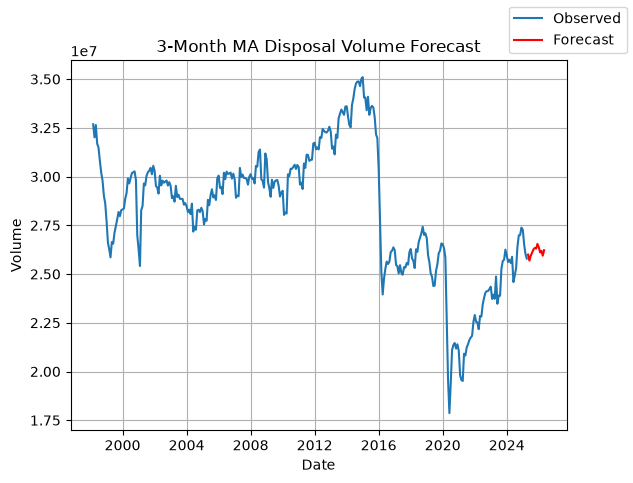

In [98]:
#This SARIMAX model uses a 3-month rolling average
#Using the SARIMAX model with the exogenous variables
#Adding the oil production and price to the disposal volume dataframe
original_df = pd.read_excel(r"C:\Users\LoganFrideley\East Texas Salt Water Disposal Company\Finance - Documents\Water Disposal History.xlsx")

monthly_water_vols = original_df[['Month/ Year', 'Total Disposed Water Volume']].copy()

# Filter out all Na values for water volumes.
monthly_water_vols = monthly_water_vols[~monthly_water_vols['Total Disposed Water Volume'].isna()]

# Changing column names to 'Water Volume'
monthly_water_vols['Water Volume'] = monthly_water_vols['Total Disposed Water Volume']

# Changing column name to Date and also making the type datetime64
monthly_water_vols['Date'] = monthly_water_vols['Month/ Year']
monthly_water_vols['Date'] = pd.to_datetime(monthly_water_vols['Date'])

# Dropping the old columns
monthly_water_vols = monthly_water_vols.drop(columns = ['Total Disposed Water Volume', 'Month/ Year'])
# Changing the order of the columns
monthly_water_vols = monthly_water_vols.loc[:, ['Date', 'Water Volume']]
monthly_water_vols['3Mo_MA'] = monthly_water_vols['Water Volume'].rolling(window=3).mean()

plt.ion()
df = pd.read_csv(r'C:\Users\LoganFrideley\OneDrive - East Texas Salt Water Disposal Company\Documents\SARIMA Project\ProductionDataQuery_monthlyTotals_ReportCsv(1).csv')


oil_prod = df[['Date', 'Barrels']].copy()
oil_prod['Date'] = pd.to_datetime(oil_prod['Date'])
oil_prod.sort_values('Date')

#FRED Brent-Crude oil pride index
df2 = pd.read_csv(r'C:\Users\LoganFrideley\OneDrive - East Texas Salt Water Disposal Company\Documents\SARIMA Project\MCOILBRENTEU.csv')

oil_price = df2[['Date', 'Price']].copy()
oil_price['Date'] = pd.to_datetime(oil_price['Date'])
oil_price.sort_values('Date')

#Combining the dataframes together for the SARIMA model
monthly_water_vols = monthly_water_vols.merge(oil_prod[['Date','Barrels']], on = 'Date', how = 'left')
monthly_water_vols = monthly_water_vols.merge(oil_price[['Date','Price']], on = 'Date', how = 'left')
monthly_water_vols = monthly_water_vols.dropna()


#Changing the dataframe to represent the last 5 years.
mask = (monthly_water_vols['Date'] >= '1998-01-01') & (monthly_water_vols['Date'] <= '2026-05-01')
subset = monthly_water_vols[mask]

#Assigning Training data set
training_mask = (subset['Date'] >= '1998-01-01') & (subset['Date'] <= '2025-04-01')
training = subset[training_mask]

#Assigning Validation data
validation_mask = (subset['Date'] >= '2025-05-01') & (subset['Date'] <= '2026-05-01')
validation = subset[validation_mask]

#SARIMAX model takes in the training data with two exogenous variables 
model = SARIMAX(
    training['3Mo_MA'], 
    k_exog = 2,
    exog = training[['Barrels', 'Price']], 
    order = (1,1,0), 
    seasonal_order = (1,0,2,12)
    
)
results = model.fit()
forecast_periods = len(validation)
forecast = results.forecast(forecast_periods, exog = validation[['Barrels', 'Price']])
r_squared = R_squared(validation['3Mo_MA'], forecast)
adjusted = adj_R_squared(validation['3Mo_MA'], forecast, monthly_water_vols)
print(f'Adjusted R-squared: {adjusted}')
print(results.summary())

fig, ax = plt.subplots()
ax.plot(training['Date'], training['3Mo_MA'], label='Observed')
ax.plot(validation['Date'], forecast, label='Forecast', color='red')
ax.set_title("3-Month MA Disposal Volume Forecast")
ax.set_xlabel("Date")
ax.set_ylabel("Volume")
ax.grid()
fig.legend()
fig.show()


C:\Users\LoganFrideley\AppData\Local\Temp\ipykernel_34588\1696492774.py:29: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  oil_prod['Date'] = pd.to_datetime(oil_prod['Date'])
C:\Users\LoganFrideley\anaconda3\envs\Analytics\Lib\site-packages\statsmodels\tsa\statespace\representation.py:374: FutureWarning: Unknown keyword arguments: dict_keys(['k_exog']).Passing unknown keyword arguments will raise a TypeError beginning in version 0.15.
  warnings.warn(msg, FutureWarning)
C:\Users\LoganFrideley\anaconda3\envs\Analytics\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'


R-squared 0.05267542990820362
Adjusted R-squared: -2.3156359953212875
                                        SARIMAX Results                                        
Dep. Variable:                                  3Mo_MA   No. Observations:                   57
Model:             SARIMAX(1, 1, 0)x(1, 0, [1, 2], 12)   Log Likelihood                -811.258
Date:                                 Thu, 03 Sep 2026   AIC                           1636.517
Time:                                         10:49:12   BIC                           1650.694
Sample:                                              0   HQIC                          1642.013
                                                  - 57                                         
Covariance Type:                                   opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Barr

C:\Users\LoganFrideley\AppData\Local\Temp\ipykernel_34588\1696492774.py:84: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


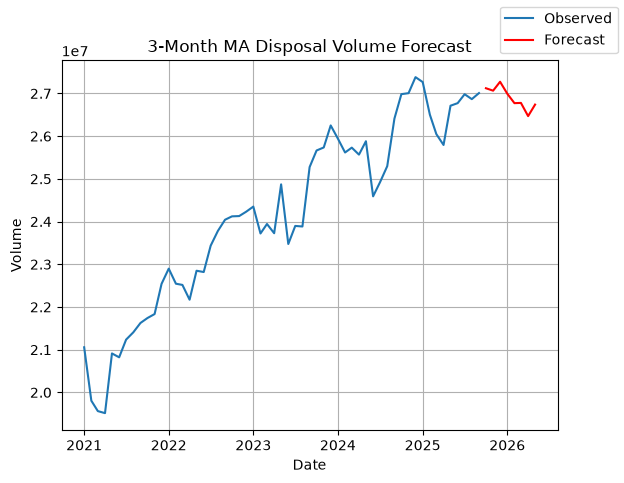

In [111]:
#This SARIMAX model uses a 3-month rolling average
#Using the SARIMAX model with the exogenous variables
#Adding the oil production and price to the disposal volume dataframe
original_df = pd.read_excel(r"C:\Users\LoganFrideley\East Texas Salt Water Disposal Company\Finance - Documents\Water Disposal History.xlsx")

monthly_water_vols = original_df[['Month/ Year', 'Total Disposed Water Volume']].copy()

# Filter out all Na values for water volumes.
monthly_water_vols = monthly_water_vols[~monthly_water_vols['Total Disposed Water Volume'].isna()]

# Changing column names to 'Water Volume'
monthly_water_vols['Water Volume'] = monthly_water_vols['Total Disposed Water Volume']

# Changing column name to Date and also making the type datetime64
monthly_water_vols['Date'] = monthly_water_vols['Month/ Year']
monthly_water_vols['Date'] = pd.to_datetime(monthly_water_vols['Date'])

# Dropping the old columns
monthly_water_vols = monthly_water_vols.drop(columns = ['Total Disposed Water Volume', 'Month/ Year'])
# Changing the order of the columns
monthly_water_vols = monthly_water_vols.loc[:, ['Date', 'Water Volume']]
monthly_water_vols['3Mo_MA'] = monthly_water_vols['Water Volume'].rolling(window=3).mean()

plt.ion()
df = pd.read_csv(r'C:\Users\LoganFrideley\OneDrive - East Texas Salt Water Disposal Company\Documents\SARIMA Project\ProductionDataQuery_monthlyTotals_ReportCsv(1).csv')


oil_prod = df[['Date', 'Barrels']].copy()
oil_prod['Date'] = pd.to_datetime(oil_prod['Date'])
oil_prod.sort_values('Date')

#FRED Brent-Crude oil pride index
df2 = pd.read_csv(r'C:\Users\LoganFrideley\OneDrive - East Texas Salt Water Disposal Company\Documents\SARIMA Project\MCOILBRENTEU.csv')

oil_price = df2[['Date', 'Price']].copy()
oil_price['Date'] = pd.to_datetime(oil_price['Date'])
oil_price.sort_values('Date')

#Combining the dataframes together for the SARIMA model
monthly_water_vols = monthly_water_vols.merge(oil_prod[['Date','Barrels']], on = 'Date', how = 'left')
monthly_water_vols = monthly_water_vols.merge(oil_price[['Date','Price']], on = 'Date', how = 'left')
monthly_water_vols = monthly_water_vols.dropna()


#Changing the dataframe to represent the last 5 years.
mask = (monthly_water_vols['Date'] >= '2021-01-01') & (monthly_water_vols['Date'] <= '2026-05-01')
subset = monthly_water_vols[mask]

#Assigning Training data set
training_mask = (subset['Date'] >= '2021-01-01') & (subset['Date'] <= '2025-09-01')
training = subset[training_mask]

#Assigning Validation data
validation_mask = (subset['Date'] >= '2025-10-01') & (subset['Date'] <= '2026-05-01')
validation = subset[validation_mask]

#SARIMAX model takes in the training data with two exogenous variables 
model = SARIMAX(
    training['3Mo_MA'], 
    k_exog = 2,
    exog = training[['Barrels', 'Price']], 
    order = (1,1,0), 
    seasonal_order = (1,0,2,12)
    
)
results = model.fit()
forecast_periods = len(validation)
forecast = results.forecast(forecast_periods, exog = validation[['Barrels', 'Price']])
r_squared = R_squared(validation['3Mo_MA'], forecast)
adjusted = adj_R_squared(validation['3Mo_MA'], forecast, monthly_water_vols)

print(f'R-squared {r_squared}')
print(f'Adjusted R-squared: {adjusted}')
print(results.summary())

fig, ax = plt.subplots()
ax.plot(training['Date'], training['3Mo_MA'], label='Observed')
ax.plot(validation['Date'], forecast, label='Forecast', color='red')
ax.set_title("3-Month MA Disposal Volume Forecast")
ax.set_xlabel("Date")
ax.set_ylabel("Volume")
ax.grid()
fig.legend()
fig.show()


C:\Users\LoganFrideley\AppData\Local\Temp\ipykernel_34588\3242452117.py:29: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  oil_prod['Date'] = pd.to_datetime(oil_prod['Date'])
C:\Users\LoganFrideley\anaconda3\envs\Analytics\Lib\site-packages\statsmodels\tsa\statespace\representation.py:374: FutureWarning: Unknown keyword arguments: dict_keys(['k_exog']).Passing unknown keyword arguments will raise a TypeError beginning in version 0.15.
  warnings.warn(msg, FutureWarning)


Adjusted R-squared: -0.6015796128477575
                                        SARIMAX Results                                        
Dep. Variable:                                  6Mo_MA   No. Observations:                  323
Model:             SARIMAX(1, 1, 0)x(1, 0, [1, 2], 12)   Log Likelihood               -4577.498
Date:                                 Thu, 03 Sep 2026   AIC                           9168.997
Time:                                         10:21:39   BIC                           9195.418
Sample:                                              0   HQIC                          9179.545
                                                 - 323                                         
Covariance Type:                                   opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Barrels        7.7970      0.366  

C:\Users\LoganFrideley\AppData\Local\Temp\ipykernel_34588\3242452117.py:82: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


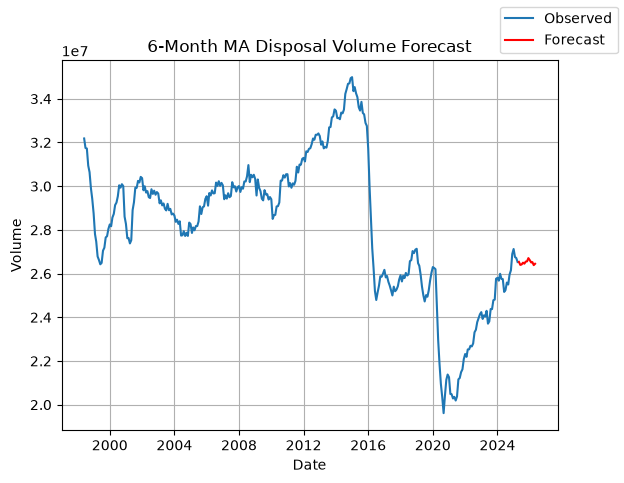

In [100]:
#This SARIMAX model uses a 6 - month moving average
#Using the SARIMAX model with the exogenous variables
#Adding the oil production and price to the disposal volume dataframe
original_df = pd.read_excel(r"C:\Users\LoganFrideley\East Texas Salt Water Disposal Company\Finance - Documents\Water Disposal History.xlsx")

monthly_water_vols = original_df[['Month/ Year', 'Total Disposed Water Volume']].copy()

# Filter out all Na values for water volumes.
monthly_water_vols = monthly_water_vols[~monthly_water_vols['Total Disposed Water Volume'].isna()]

# Changing column names to 'Water Volume'
monthly_water_vols['Water Volume'] = monthly_water_vols['Total Disposed Water Volume']

# Changing column name to Date and also making the type datetime64
monthly_water_vols['Date'] = monthly_water_vols['Month/ Year']
monthly_water_vols['Date'] = pd.to_datetime(monthly_water_vols['Date'])

# Dropping the old columns
monthly_water_vols = monthly_water_vols.drop(columns = ['Total Disposed Water Volume', 'Month/ Year'])
# Changing the order of the columns
monthly_water_vols = monthly_water_vols.loc[:, ['Date', 'Water Volume']]
monthly_water_vols['6Mo_MA'] = monthly_water_vols['Water Volume'].rolling(window=6).mean()

plt.ion()
df = pd.read_csv(r'C:\Users\LoganFrideley\OneDrive - East Texas Salt Water Disposal Company\Documents\SARIMA Project\ProductionDataQuery_monthlyTotals_ReportCsv(1).csv')


oil_prod = df[['Date', 'Barrels']].copy()
oil_prod['Date'] = pd.to_datetime(oil_prod['Date'])
oil_prod.sort_values('Date')

#FRED Brent-Crude oil pride index
df2 = pd.read_csv(r'C:\Users\LoganFrideley\OneDrive - East Texas Salt Water Disposal Company\Documents\SARIMA Project\MCOILBRENTEU.csv')

oil_price = df2[['Date', 'Price']].copy()
oil_price['Date'] = pd.to_datetime(oil_price['Date'])
oil_price.sort_values('Date')

#Combining the dataframes together for the SARIMA model
monthly_water_vols = monthly_water_vols.merge(oil_prod[['Date','Barrels']], on = 'Date', how = 'left')
monthly_water_vols = monthly_water_vols.merge(oil_price[['Date','Price']], on = 'Date', how = 'left')
monthly_water_vols = monthly_water_vols.dropna()


#Changing the dataframe to represent the last 5 years.
mask = (monthly_water_vols['Date'] >= '1998-01-01') & (monthly_water_vols['Date'] <= '2026-05-01')
subset = monthly_water_vols[mask]

#Assigning Training data set
training_mask = (subset['Date'] >= '1998-01-01') & (subset['Date'] <= '2025-04-01')
training = subset[training_mask]

#Assigning Validation data
validation_mask = (subset['Date'] >= '2025-05-01') & (subset['Date'] <= '2026-05-01')
validation = subset[validation_mask]

#SARIMAX model takes in the training data with two exogenous variables 
model = SARIMAX(
    training['6Mo_MA'], 
    k_exog = 2,
    exog = training[['Barrels', 'Price']], 
    order = (1,1,0), 
    seasonal_order = (1,0,2,12)
    
)
results = model.fit()
forecast_periods = len(validation)
forecast = results.forecast(forecast_periods, exog = validation[['Barrels', 'Price']])
r_squared = R_squared(validation['6Mo_MA'], forecast)
adjusted = adj_R_squared(validation['6Mo_MA'], forecast, monthly_water_vols)
print(f'Adjusted R-squared: {adjusted}')
print(results.summary())

fig, ax = plt.subplots()
ax.plot(training['Date'], training['6Mo_MA'], label='Observed')
ax.plot(validation['Date'], forecast, label='Forecast', color='red')
ax.set_title("6-Month MA Disposal Volume Forecast")
ax.set_xlabel("Date")
ax.set_ylabel("Volume")
ax.grid()
fig.legend()
fig.show()


C:\Users\LoganFrideley\AppData\Local\Temp\ipykernel_34588\946366821.py:29: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  oil_prod['Date'] = pd.to_datetime(oil_prod['Date'])
C:\Users\LoganFrideley\anaconda3\envs\Analytics\Lib\site-packages\statsmodels\tsa\statespace\representation.py:374: FutureWarning: Unknown keyword arguments: dict_keys(['k_exog']).Passing unknown keyword arguments will raise a TypeError beginning in version 0.15.
  warnings.warn(msg, FutureWarning)


R-squared 0.06574522583880815
Adjusted R-squared: -0.6015796128477575
                                        SARIMAX Results                                        
Dep. Variable:                                  6Mo_MA   No. Observations:                  323
Model:             SARIMAX(1, 1, 0)x(1, 0, [1, 2], 12)   Log Likelihood               -4577.498
Date:                                 Thu, 03 Sep 2026   AIC                           9168.997
Time:                                         10:50:07   BIC                           9195.418
Sample:                                              0   HQIC                          9179.545
                                                 - 323                                         
Covariance Type:                                   opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Barr

C:\Users\LoganFrideley\AppData\Local\Temp\ipykernel_34588\946366821.py:84: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


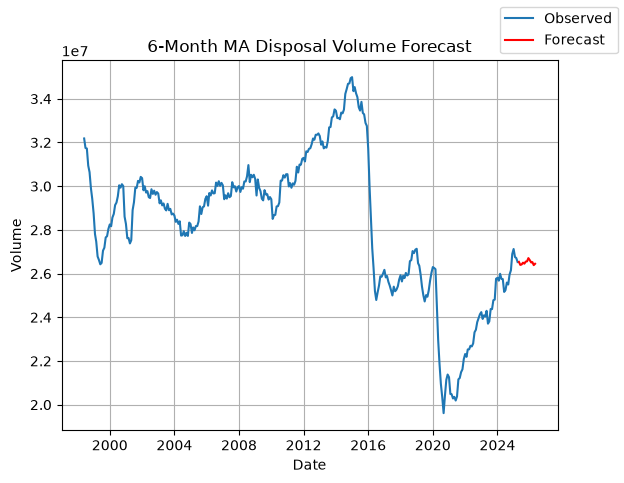

In [112]:
#This SARIMAX model uses a 6 - month moving average
#Using the SARIMAX model with the exogenous variables
#Adding the oil production and price to the disposal volume dataframe
original_df = pd.read_excel(r"C:\Users\LoganFrideley\East Texas Salt Water Disposal Company\Finance - Documents\Water Disposal History.xlsx")

monthly_water_vols = original_df[['Month/ Year', 'Total Disposed Water Volume']].copy()

# Filter out all Na values for water volumes.
monthly_water_vols = monthly_water_vols[~monthly_water_vols['Total Disposed Water Volume'].isna()]

# Changing column names to 'Water Volume'
monthly_water_vols['Water Volume'] = monthly_water_vols['Total Disposed Water Volume']

# Changing column name to Date and also making the type datetime64
monthly_water_vols['Date'] = monthly_water_vols['Month/ Year']
monthly_water_vols['Date'] = pd.to_datetime(monthly_water_vols['Date'])

# Dropping the old columns
monthly_water_vols = monthly_water_vols.drop(columns = ['Total Disposed Water Volume', 'Month/ Year'])
# Changing the order of the columns
monthly_water_vols = monthly_water_vols.loc[:, ['Date', 'Water Volume']]
monthly_water_vols['6Mo_MA'] = monthly_water_vols['Water Volume'].rolling(window=6).mean()

plt.ion()
df = pd.read_csv(r'C:\Users\LoganFrideley\OneDrive - East Texas Salt Water Disposal Company\Documents\SARIMA Project\ProductionDataQuery_monthlyTotals_ReportCsv(1).csv')


oil_prod = df[['Date', 'Barrels']].copy()
oil_prod['Date'] = pd.to_datetime(oil_prod['Date'])
oil_prod.sort_values('Date')

#FRED Brent-Crude oil pride index
df2 = pd.read_csv(r'C:\Users\LoganFrideley\OneDrive - East Texas Salt Water Disposal Company\Documents\SARIMA Project\MCOILBRENTEU.csv')

oil_price = df2[['Date', 'Price']].copy()
oil_price['Date'] = pd.to_datetime(oil_price['Date'])
oil_price.sort_values('Date')

#Combining the dataframes together for the SARIMA model
monthly_water_vols = monthly_water_vols.merge(oil_prod[['Date','Barrels']], on = 'Date', how = 'left')
monthly_water_vols = monthly_water_vols.merge(oil_price[['Date','Price']], on = 'Date', how = 'left')
monthly_water_vols = monthly_water_vols.dropna()


#Changing the dataframe to represent the last 5 years.
mask = (monthly_water_vols['Date'] >= '1998-01-01') & (monthly_water_vols['Date'] <= '2026-05-01')
subset = monthly_water_vols[mask]

#Assigning Training data set
training_mask = (subset['Date'] >= '1998-01-01') & (subset['Date'] <= '2025-04-01')
training = subset[training_mask]

#Assigning Validation data
validation_mask = (subset['Date'] >= '2025-05-01') & (subset['Date'] <= '2026-05-01')
validation = subset[validation_mask]

#SARIMAX model takes in the training data with two exogenous variables 
model = SARIMAX(
    training['6Mo_MA'], 
    k_exog = 2,
    exog = training[['Barrels', 'Price']], 
    order = (1,1,0), 
    seasonal_order = (1,0,2,12)
    
)
results = model.fit()
forecast_periods = len(validation)
forecast = results.forecast(forecast_periods, exog = validation[['Barrels', 'Price']])
r_squared = R_squared(validation['6Mo_MA'], forecast)
adjusted = adj_R_squared(validation['6Mo_MA'], forecast, monthly_water_vols)

print(f'R-squared {r_squared}')
print(f'Adjusted R-squared: {adjusted}')
print(results.summary())

fig, ax = plt.subplots()
ax.plot(training['Date'], training['6Mo_MA'], label='Observed')
ax.plot(validation['Date'], forecast, label='Forecast', color='red')
ax.set_title("6-Month MA Disposal Volume Forecast")
ax.set_xlabel("Date")
ax.set_ylabel("Volume")
ax.grid()
fig.legend()
fig.show()
